# California Housing Price Prediction

A complete, reproducible data science project that explores and models median house prices across California districts.

- **Research question:** Can we predict a district's median house value from features such as income, house age, rooms, and population? Which features matter most?
- **Dataset:** `sklearn.datasets.fetch_california_housing` (1990 U.S. Census, public, **BSD-3-Clause** license), 20,640 rows.
- **Tools:** pandas, NumPy, matplotlib, seaborn, scikit-learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
%matplotlib inline

## 1. Load the data

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame
print(f'{df.shape[0]:,} rows x {df.shape[1]} columns')
print('Missing values:', int(df.isna().sum().sum()))
df.head()

20,640 rows x 9 columns
Missing values: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Exploratory Data Analysis

In [3]:
df['MedHouseVal'].describe().round(2)

count    20640.00
mean         2.07
std          1.15
min          0.15
25%          1.20
50%          1.80
75%          2.65
max          5.00
Name: MedHouseVal, dtype: float64

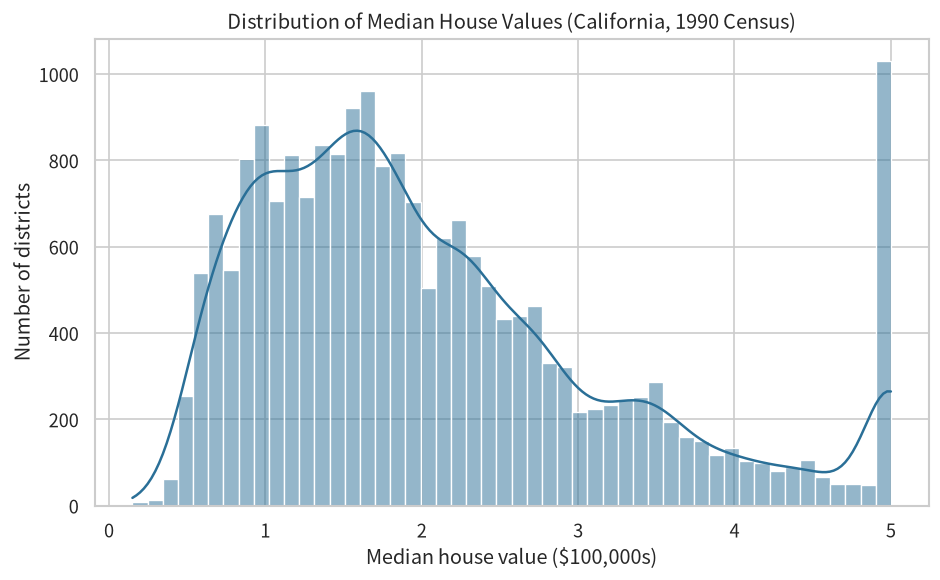

In [4]:
fig, ax = plt.subplots(figsize=(8,5))
sns.histplot(df['MedHouseVal'], bins=50, kde=True, ax=ax, color='#2a6f97')
ax.set_title('Distribution of Median House Values (California, 1990 Census)')
ax.set_xlabel('Median house value ($100,000s)')
ax.set_ylabel('Number of districts')
plt.tight_layout()
plt.savefig('visualizations/fig_price_distribution.png', bbox_inches='tight')
plt.show()

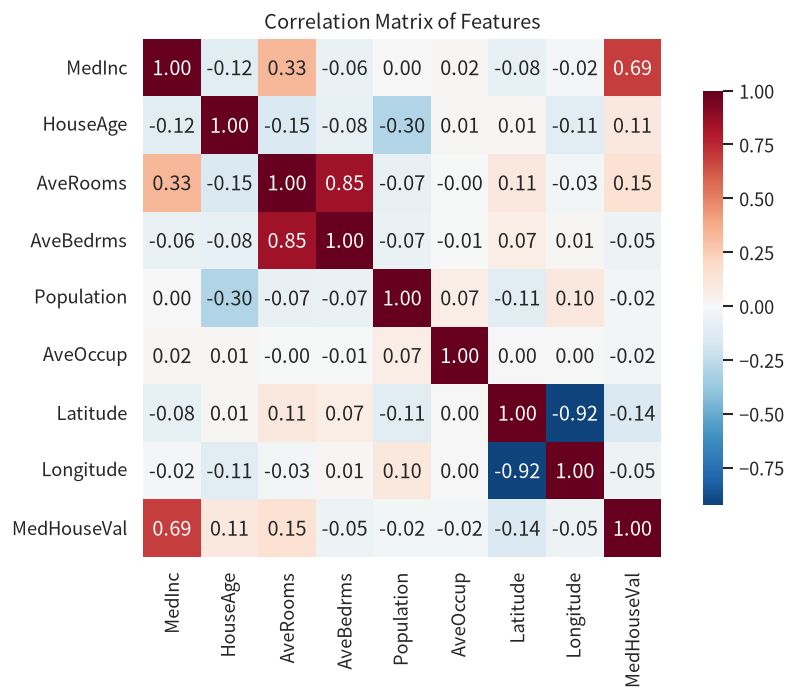

In [5]:
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True,
            ax=ax, cbar_kws={'shrink':0.8})
ax.set_title('Correlation Matrix of Features')
plt.tight_layout()
plt.savefig('visualizations/fig_correlation_heatmap.png', bbox_inches='tight')
plt.show()

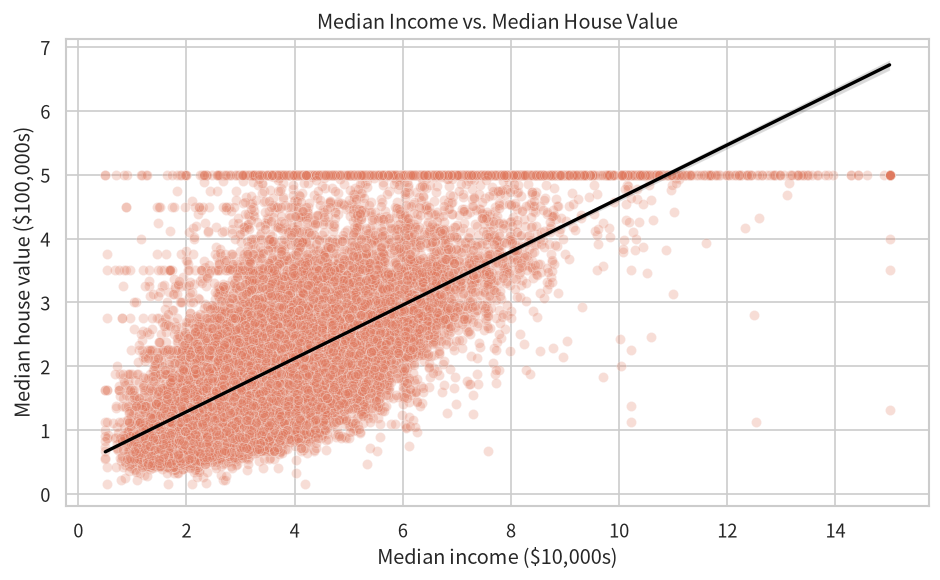

In [6]:
fig, ax = plt.subplots(figsize=(8,5))
sns.scatterplot(x='MedInc', y='MedHouseVal', data=df, alpha=0.25, ax=ax, color='#e07a5f')
sns.regplot(x='MedInc', y='MedHouseVal', data=df, scatter=False, color='black', ax=ax, line_kws={'lw':2})
ax.set_title('Median Income vs. Median House Value')
ax.set_xlabel('Median income ($10,000s)')
ax.set_ylabel('Median house value ($100,000s)')
plt.tight_layout()
plt.savefig('visualizations/fig_income_vs_price.png', bbox_inches='tight')
plt.show()

## 3. Modelling

In [7]:
X = df.drop(columns='MedHouseVal')
y = df['MedHouseVal']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
}
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rmse = root_mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    results[name] = (model, pred, rmse, r2)
    print(f'{name:<18} RMSE={rmse:.3f}  R2={r2:.3f}')

Linear Regression  RMSE=0.746  R2=0.576


Random Forest      RMSE=0.504  R2=0.806


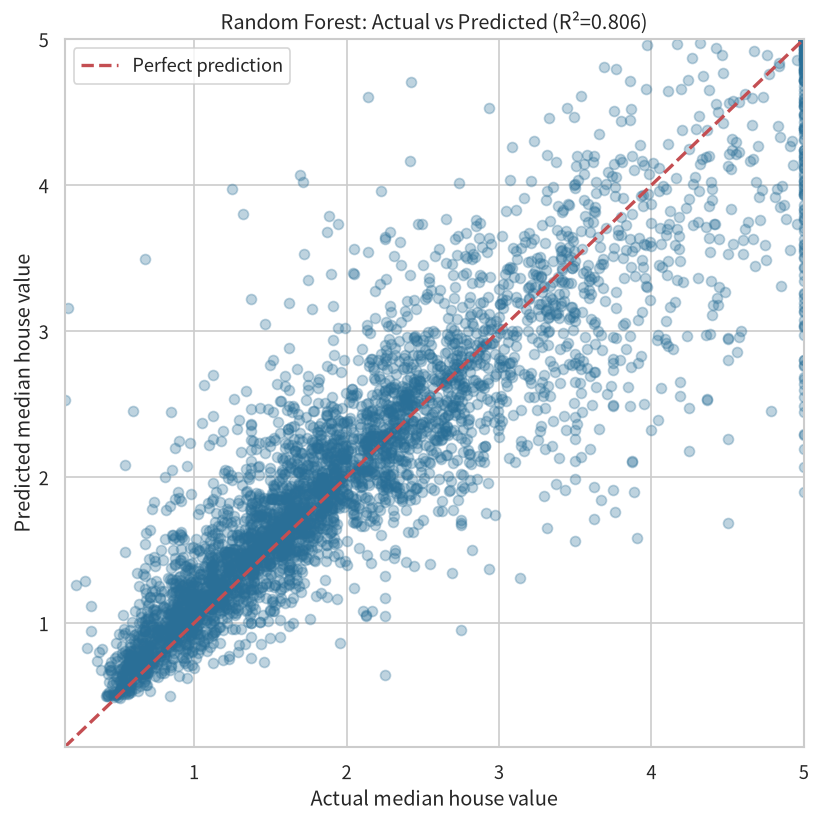

In [8]:
model, pred, rmse, r2 = results['Random Forest']
fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(y_test, pred, alpha=0.3, color='#2a6f97')
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
ax.plot(lims, lims, 'r--', lw=2, label='Perfect prediction')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Actual median house value')
ax.set_ylabel('Predicted median house value')
ax.set_title(f'Random Forest: Actual vs Predicted (R\u00b2={r2:.3f})')
ax.legend()
plt.tight_layout()
plt.savefig('visualizations/fig_actual_vs_predicted.png', bbox_inches='tight')
plt.show()

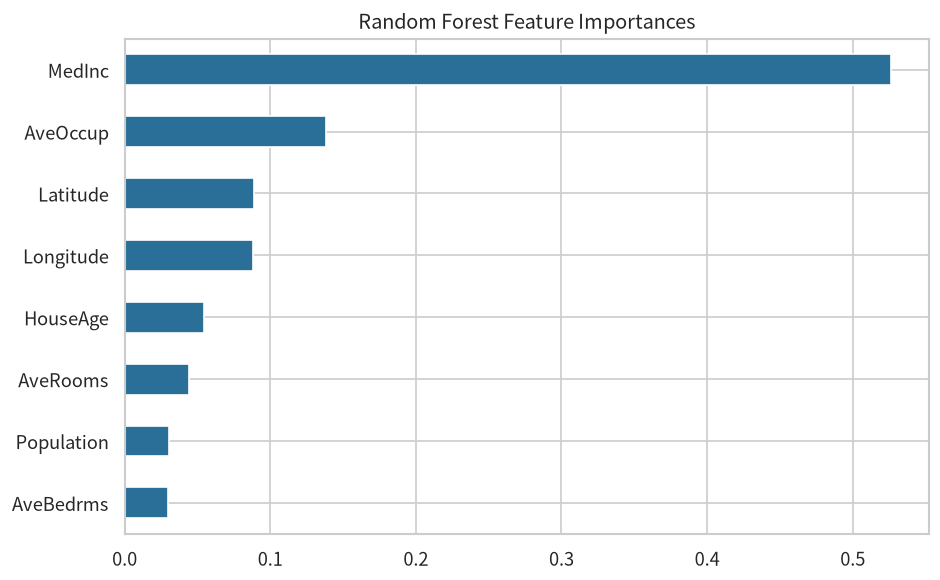

In [9]:
rf = results['Random Forest'][0]
fig, ax = plt.subplots(figsize=(8,5))
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(ax=ax, color='#2a6f97')
ax.set_title('Random Forest Feature Importances')
plt.tight_layout()
plt.savefig('visualizations/fig_feature_importance.png', bbox_inches='tight')
plt.show()

## 4. Conclusions

- **Median income is the strongest predictor** (corr ≈ 0.69; top feature in importance).
- House values are **right-skewed** — most districts are affordable, with a long tail of high-value areas.
- **Random Forest outperforms Linear Regression** (R² 0.806 vs 0.576; RMSE 0.504 vs 0.746), showing a non-linear relationship.

**Limitation:** the data is from the **1990 census**, so findings may not reflect today's market; context features (schools, crime, amenities) are missing.